## MNIST handwritten digits prediction

The MNIST (Modified National Institute of Standards and Technology) digits dataset is a widely used dataset in the field of machine learning and computer vision. It is commonly used for training and testing image processing systems, particularly in the context of handwritten digit recognition.

<img src="https://miro.medium.com/max/800/1*LyRlX__08q40UJohhJG9Ow.png" align="left" width="600">

### Import Python libraries

In [1]:
# Libraries
import os
import logging
import platform
import warnings
from datetime import datetime
from platform import python_version

import numpy as np
import matplotlib.pyplot as plt

# Set TensorFlow log level to suppress warnings (must be set before
# TensorFlow is imported)
logging.disable(logging.WARNING)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# TensorFlow and Keras (imported after setting the log level)
# pylint: disable=wrong-import-position
from tensorflow import keras
from tensorflow.keras import layers

# pylint: enable=wrong-import-position

# Ignore warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

I0000 00:00:1792928965.540520   29920 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792928965.698834   29920 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792928998.438270   29920 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792928998.439970   29920 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/workspaces/python_machine_learning_basics/08_Neural_Networks


### Prepare the data

### AUFGABE UND KONTEXT:

- Wir bereiten **MNIST-Bilder handgeschriebener Ziffern** für ein Convolutional Neural Network (CNN) vor. Ziel ist, jedes Bild einer Ziffer von **0 bis 9** zuzuordnen (`num_classes = 10`).
- `load_data()` lädt die bereits getrennten **60’000 Trainingsbilder und 10’000 Testbilder** samt zugehörigen Ziffern.
- Jedes Bild hat **28 × 28 Pixel**. Durch die Umwandlung in `float32` und Division durch 255 werden die Pixelwerte von 0–255 auf **0–1 skaliert**.
- `expand_dims(..., -1)` ergänzt die Kanalachse: **`(28, 28, 1)`** bedeutet Höhe, Breite und ein Graustufenkanal. Die Trainingsdaten haben danach die Form `(60000, 28, 28, 1)`.
- `to_categorical()` wandelt die Zielziffern in **One-Hot-Vektoren mit zehn Einträgen** um: Nur die Position der richtigen Ziffer ist 1, alle anderen sind 0. Das passt zur späteren Ausgabe mit zehn Klassen.

VERLANGT: Die vorgegebene Zelle ausführen und damit Bilder und Zielwerte für das CNN vorbereiten. Hier wird noch kein Modell trainiert.

In [3]:
# Model / data parameters
num_classes = 10                                                       #Legt die zehn Zielklassen fest: Ziffern von 0 bis 9
input_shape = (28, 28, 1)                                              #Beschreibt ein Bild: 28 Pixel hoch, 28 Pixel breit, ein Graustufenkanal

# The data, split between train and test sets
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()  #Lädt Trainings- und Testbilder (X) samt zugehörigen Ziffern (y)

# Scale images to the [0, 1] range
X_train = X_train.astype("float32") / 255                              #Wandelt Trainingspixel in Kommazahlen um und skaliert ihre Werte von 0–255 auf 0–1
X_test = X_test.astype("float32") / 255                                #Bereitet die Testpixel auf dieselbe Weise vor

# Make sure images have shape (28, 28, 1)
X_train = np.expand_dims(X_train, -1)                                  #Ergänzt die Kanalachse: aus (60000, 28, 28) wird (60000, 28, 28, 1)
X_test = np.expand_dims(X_test, -1)                                    #Ergänzt auch bei den Testbildern den Graustufenkanal für die CNN-Eingabe
print("X_train shape:", X_train.shape)                                 #Zeigt die Datenform: Anzahl Bilder, Höhe, Breite und Anzahl Kanäle
print(X_train.shape[0], "train samples")                               #Gibt die Anzahl der Trainingsbilder aus: 60’000
print(X_test.shape[0], "test samples")                                 #Gibt die Anzahl der Testbilder aus: 10’000

# Convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)             #Codiert jede Trainingsziffer als zehn Einträge: richtige Klassenposition = 1, sonst 0
y_test = keras.utils.to_categorical(y_test, num_classes)               #Codiert die Testziffern ebenso, passend zur späteren Ausgabe mit zehn Klassen

X_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


### Show single handwritten digits

### AUFGABE UND KONTEXT:

- Wir zeigen ein einzelnes vorbereitetes MNIST-Bild an, um die Eingabedaten des CNN anzuschauen.
- `X_train[2]` wählt das **dritte Trainingsbild**, da Python bei 0 zu zählen beginnt. Der Index bezeichnet die Bildposition, nicht die dargestellte Ziffer.
- `imshow(..., cmap='gray')` stellt die Pixel als Graustufenbild dar; `figsize=(2, 2)` bestimmt die Anzeigegrösse.
- Die ausgegebene Form **`(28, 28, 1)`** bedeutet: 28 Pixel Höhe, 28 Pixel Breite und ein Graustufenkanal.

VERLANGT: Die Zelle ausführen, das Bild und seine Form betrachten. Durch Ändern des Index lassen sich weitere Ziffernbilder anzeigen

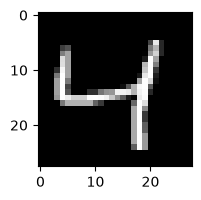

In [4]:
# Show single digit image
image = X_train[2]                                      #Change index in [] to show other digits; wählt das dritte Trainingsbild, da die Zählung bei 0 beginnt
# Figure showing the digit as a grey-scale image
plt.figure(figsize=(2, 2))                              #Erstellt eine Zeichenfläche mit 2 × 2 Zoll; die Bilddaten bleiben unverändert
plt.imshow(image, cmap='gray')                          #Stellt die Pixelwerte des ausgewählten Bildes als Graustufen dar
plt.show()                                              #Zeigt das Ziffernbild an

In [5]:
# Show shape of single digit image
print(X_train[2].shape)                                 #Gibt (28, 28, 1) aus: 28 Pixel Höhe, 28 Pixel Breite und ein Graustufenkanal

(28, 28, 1)


### Initialize the model 

### AUFGABE UND KONTEXT:

- Wir definieren ein **Convolutional Neural Network (CNN)**, das die vorbereiteten Ziffernbilder einer der zehn Klassen 0–9 zuordnen soll. `Sequential` verbindet die Schichten nacheinander.
- **Input:** Erwartet Bilder mit der Form `(28, 28, 1)`.
- **Conv2D:** Zuerst 32, danach 64 lernbare Filter der Grösse 3 × 3 erkennen lokale Bildmuster, etwa Kanten und Striche. `relu` setzt negative Aktivierungswerte auf 0 und ermöglicht nichtlineare Zusammenhänge.
- **MaxPooling2D:** Übernimmt jeweils den grössten Wert eines 2 × 2-Bereichs. Dadurch werden die Merkmalskarten räumlich verkleinert.
- **Flatten:** Wandelt die Merkmalskarten in einen eindimensionalen Vektor um.
- **Dropout(0.5):** Deaktiviert während des Trainings zufällig 50 % der Eingabewerte dieser Schicht und hilft, Overfitting zu reduzieren. Bei Vorhersagen ist Dropout ausgeschaltet.
- **Dense mit Softmax:** Liefert zehn geschätzte Klassenwahrscheinlichkeiten, deren Summe 1 ist. Die höchste bestimmt die vorhergesagte Ziffer.

VERLANGT: Die Zelle ausführen, um die Modellarchitektur zu erstellen. Das Modell wird hier noch nicht trainiert. Optional zeigt `model.summary()` die Schichten, Ausgabeformen und Parameterzahlen

In [6]:
# Linear stack of layers
model = keras.Sequential(                                           #Verbindet die folgenden Schichten nacheinander zu einem CNN
    [
        keras.Input(shape=input_shape),                             #Erwartet Bilder mit 28 × 28 Pixeln und einem Graustufenkanal
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),   #Lernt 32 Filter für lokale Bildmuster; ReLU setzt negative Aktivierungen auf 0
        layers.MaxPooling2D(pool_size=(2, 2)),                      #Verkleinert die Merkmalskarten: übernimmt das Maximum jedes 2 × 2-Bereichs
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),   #Lernt 64 Filter, die Muster aus den vorherigen Merkmalskarten kombinieren
        layers.MaxPooling2D(pool_size=(2, 2)),                      #Verkleinert die Merkmalskarten erneut und reduziert den weiteren Rechenaufwand
        layers.Flatten(),                                           #Formt die Merkmalskarten zu einem eindimensionalen Vektor um
        layers.Dropout(0.5),                                        #Setzt beim Training zufällig 50 % der Werte auf 0, um Overfitting zu reduzieren
        layers.Dense(num_classes, activation="softmax"),            #Liefert zehn Klassenwahrscheinlichkeiten für die Ziffern 0–9; ihre Summe ist 1
    ]
)
# model.summary()                                                   #Entferne das erste #, um Schichten, Ausgabeformen und Parameterzahlen anzuzeigen

### Train the model

### AUFGABE UND KONTEXT:

- Wir konfigurieren und trainieren das zuvor erstellte CNN mit den vorbereiteten MNIST-Daten.
- **`batch_size=128`:** Das Modell verarbeitet bis zu 128 Bilder gemeinsam, bevor es seine Gewichte aktualisiert.
- **`epochs=5`:** Die zum Lernen verwendeten Bilder werden fünfmal durchlaufen.
- **`compile()`:** Legt das Lernverfahren fest: `categorical_crossentropy` misst den Fehler zwischen den vorhergesagten Wahrscheinlichkeiten und den One-Hot-Zielwerten; der Optimierer `adam` passt die Gewichte an. `accuracy` zeigt den Anteil richtig erkannter Ziffern.
- **`fit()`** startet das Training. Mit `validation_split=0.1` werden 10 % der 60’000 Bilder zur Validierung zurückgehalten: **54’000 zum Lernen, 6’000 zur Validierung**. Die separaten Testdaten bleiben unberührt.
- Pro Epoche erscheinen **Loss und Accuracy für Training und Validierung**. Sinkender Loss und steigende Accuracy zeigen Verbesserungen; verbessert sich nur das Training, während die Validierung schlechter wird, deutet das auf Overfitting hin.

VERLANGT: Die vorgegebene Zelle ausführen und die Entwicklung der Trainings- und Validierungswerte über die fünf Epochen beobachten

In [7]:
# Define batch size and epochs
batch_size = 128                                                                #Verarbeitet bis zu 128 Bilder gemeinsam vor jeder Aktualisierung der Gewichte
epochs = 5                                                                      #Durchläuft die zum Lernen verwendeten Bilder insgesamt fünfmal

# Compile the model
model.compile(                                                                  #Konfiguriert das zuvor erstellte CNN für das Training
    loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"]     #Fehler für One-Hot-Ziele; Adam passt Gewichte an; 
                                                                                #Accuracy misst den Anteil richtiger Klassen
)

# Train the model
model.fit(                                                                      #Startet das Lernen und zeigt pro Epoche Trainings- und Validierungswerte
    X_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1#Lernt mit 54’000 Bildern; hält 6’000 zur Validierung ohne 
                                                                                #Gewichtsanpassung zurück
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.8863 - loss: 0.3717 - val_accuracy: 0.9788 - val_loss: 0.0834
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.9657 - loss: 0.1112 - val_accuracy: 0.9840 - val_loss: 0.0566
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 40ms/step - accuracy: 0.9744 - loss: 0.0835 - val_accuracy: 0.9870 - val_loss: 0.0485
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.9787 - loss: 0.0702 - val_accuracy: 0.9888 - val_loss: 0.0397
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9807 - loss: 0.0606 - val_accuracy: 0.9885 - val_loss: 0.0396


### Evaluate the trained model

### AUFGABE UND KONTEXT:

- Wir bewerten das trainierte CNN auf den **10’000 Testbildern**, die weder zum Lernen noch zur Validierung verwendet wurden.
- `model.evaluate()` berechnet die zuvor festgelegte Verlustfunktion und Accuracy, ohne die Gewichte zu verändern.
- **`score[0]` – Test Loss:** Categorical Crossentropy; kleinere Werte sind besser. Sie berücksichtigt auch, wie sicher das Modell seine Vorhersagen abgibt.
- **`score[1]` – Test Accuracy:** Anteil richtig erkannter Ziffern. Beispielsweise bedeutet `0.98`, dass 98 % der Testbilder korrekt klassifiziert wurden.
- `verbose=0` unterdrückt die Fortschrittsanzeige; `round(..., 4)` rundet die ausgegebenen Werte auf vier Dezimalstellen.

VERLANGT: Die Zelle ausführen und anhand von Test Loss und Test Accuracy beurteilen, wie gut das Modell bisher unbekannte Ziffernbilder erkennt

In [8]:
# Calculate the test loss and accuracy
score = model.evaluate(X_test, y_test, verbose=0)  #Berechnet Loss und Accuracy auf den Testdaten ohne Gewichtsanpassung; unterdrückt die Fortschrittsanzeige
print("Test loss:", round(score[0], 4))            #Zeigt den Testfehler (Crossentropy) auf vier Dezimalstellen; kleinere Werte sind besser
print("Test accuracy:", round(score[1], 4))        #Zeigt den Anteil richtig erkannter Testziffern; beispielsweise entspricht 0.98 einer Genauigkeit von 98 %

Test loss: 0.0374
Test accuracy: 0.9884


### Jupyter notebook --footer info-- (please always provide this at the end of each submitted notebook)

In [ ]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')